# TP Diseño experimental de Machine Learning
**LUDI, Noah** · Data Science · 05/11/2026 · Versión 1

Se trabaja con [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), 344 observaciones de pingüinos de tres especies, islas y años de muestreo. Fuente de Allison Horst, Alison Hill y Kristen Gorman; licencia CC0.

[1. Formulación](#ejercicio-1) · [2. Tres tareas](#ejercicio-2) · [3. Auditoría](#ejercicio-3) · [4. Particiones](#ejercicio-4) · [5. Fugas](#ejercicio-5) · [6. Pipelines](#ejercicio-6) · [7. Referencias](#ejercicio-7) · [8. Clasificación](#ejercicio-8) · [9. Regresión](#ejercicio-9) · [10. Clustering](#ejercicio-10) · [11. Validación](#ejercicio-11) · [12. Complejidad](#ejercicio-12) · [13. Prueba final](#ejercicio-13)

**Entorno:** Python 3.12 con `pandas`, `numpy`, `matplotlib` y `scikit-learn==1.7.2`. Si falta alguna biblioteca, instalarla con `%pip install pandas numpy matplotlib scikit-learn==1.7.2` en una celda de configuración. Luego reiniciar y ejecutar todo en orden.

In [1]:
import platform
import tempfile
from datetime import datetime, timezone
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    log_loss, mean_absolute_error, mean_squared_error, r2_score,
    silhouette_samples, silhouette_score,
)
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

SEMILLA = 42
MEDIDAS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
MEDIDAS_REG = MEDIDAS[:-1]
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 90)
plt.style.use("seaborn-v0_8-whitegrid")

display(pd.Series({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
    "semilla": SEMILLA,
}).to_frame("versión / valor"))

,versión / valor
Python,3.12.4
pandas,3.0.5
numpy,2.5.2
matplotlib,3.11.1
scikit-learn,1.7.2
semilla,42


## Protocolo previo

La unidad es un pingüino individual. El caso nuevo es otro individuo de la misma población de referencia: islas y años representados en el dataset, bajo un procedimiento de medición comparable.

Antes de explorar se reserva el 20 % para prueba, estratificado por especie y con semilla 42. El desarrollo se valida en cinco folds compartidos entre modelos. Imputación y escalado se ajustan dentro de cada fold.

La clasificación usa las cuatro medidas corporales; la regresión predice masa con las otras tres. Isla, sexo y año quedan como contexto; especie se usa solo después de formar clusters. La extensión de regresión incorpora especie de manera explícita.

Se elegirá por F1 macro de validación. Si las diferencias no superan 0,005, se prefiere regresión logística; entre árboles comparables, menor profundidad. La prueba se consulta una sola vez, después de fijar la configuración. Las extensiones opcionales por isla y año quedan fuera de este trabajo.

<a id="ejercicio-1"></a>
## 1. Paradigma, tarea, algoritmo y decisión

| Situación | Paradigma | Tarea | Salida | Algoritmos posibles | Decisión |
|---|---|---|---|---|---|
| Estimar especie | Supervisado | Clasificación | Especie predicha | Regresión logística, árbol | Priorizar verificación de individuos |
| Estimar masa | Supervisado | Regresión | Masa en gramos | Regresión lineal, árbol de regresión | Evaluar condición corporal |
| Agrupar perfiles | No supervisado | Clustering | Grupo morfológico | K-means, jerárquico | Organizar muestreos |
| Pocas etiquetas verificadas | Semisupervisado | Clasificación | Especie estimada usando datos con y sin etiqueta | Label spreading, autoentrenamiento | Elegir qué etiquetas revisar |

El experimento también depende de la población, las variables disponibles al predecir, la partición, los costos de error y la métrica. Una predicción es una salida del modelo; una decisión combina esa salida con un criterio de acción.

Una misma familia, como los árboles, permite clasificación y regresión. A su vez, clasificar especies puede hacerse con regresión logística o vecinos cercanos. Codificar especies con 0, 1 y 2 no vuelve continua la tarea: los números representan categorías sin distancia ni orden natural.

<a id="ejercicio-2"></a>
## 2. Tres tareas sobre los mismos datos

| Elemento | Clasificación | Regresión | Clustering |
|---|---|---|---|
| Uso | Reconocer especie | Estimar masa sin balanza | Describir perfiles corporales |
| Unidad | Un pingüino | Un pingüino | Un pingüino |
| Entradas | Cuatro medidas corporales | Pico y aleta; sin masa | Cuatro medidas corporales |
| Objetivo | `species` | `body_mass_g` | No hay etiqueta objetivo |
| Salida | Especie y probabilidades | Gramos estimados | Identificador de grupo |
| Error relevante | Confundir especies, sobre todo la menos frecuente | Errores grandes de masa | Grupos inestables o sin utilidad interpretable |

Cambian el objetivo, las métricas y el uso de las columnas. La masa es objetivo en regresión: incluirla como predictor revelaría la respuesta. En clustering se oculta especie durante la construcción y selección de grupos; luego sirve para interpretarlos. Los resultados se limitan a esta población y no prueban que funcionen en otras especies, regiones o condiciones.

<a id="ejercicio-3"></a>
## 3. Auditoría y reserva temprana

La documentación describe una observación por individuo y no aporta un identificador explícito del animal. Se revisan estructura y filas idénticas antes de separar; el resto de la auditoría usa únicamente desarrollo.

In [2]:
URL = (
    "https://raw.githubusercontent.com/allisonhorst/"
    "palmerpenguins/master/inst/extdata/penguins.csv"
)
with urlopen(URL, timeout=60) as respuesta:
    csv_original = respuesta.read()
datos = pd.read_csv(BytesIO(csv_original))
original = datos.copy(deep=True)
assert datos.shape == (344, 8)
assert datos["species"].notna().all()
assert datos.index.is_unique

display(pd.Series({
    "fuente": URL,
    "fecha_acceso_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sha256_csv": sha256(csv_original).hexdigest(),
    "filas": len(datos),
    "columnas": len(datos.columns),
    "filas_idénticas": int(datos.duplicated().sum()),
}).to_frame("valor"))
display(datos.dtypes.to_frame("tipo"))
print("Objetivo disponible:", datos["species"].notna().sum())

idx_desarrollo, idx_prueba = train_test_split(
    datos.index, test_size=0.20, stratify=datos["species"], random_state=SEMILLA
)
desarrollo = datos.loc[idx_desarrollo].copy()
prueba = datos.loc[idx_prueba].copy()
assert set(idx_desarrollo).isdisjoint(idx_prueba)
assert set(idx_desarrollo) | set(idx_prueba) == set(datos.index)

directorio_indices = Path(tempfile.mkdtemp(prefix="penguins_"))
pd.Series(idx_desarrollo, name="indice").to_csv(directorio_indices / "desarrollo.csv", index=False)
pd.Series(idx_prueba, name="indice").to_csv(directorio_indices / "prueba.csv", index=False)
assert pd.read_csv(directorio_indices / "prueba.csv")["indice"].tolist() == idx_prueba.tolist()
display(pd.DataFrame({
    "partición": ["desarrollo", "prueba"],
    "cantidad": [len(desarrollo), len(prueba)],
    "índices": [idx_desarrollo.tolist(), idx_prueba.tolist()],
}))
print("Índices guardados en archivos temporales; intersección vacía y cobertura completa.")

,valor
fuente,https://raw.githubusercontent.com/allisonhorst/palmerpenguins/master/inst/extdata/peng...
fecha_acceso_utc,2026-11-05T17:07:49+00:00
sha256_csv,f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93
filas,344
columnas,8
filas_idénticas,0


,tipo
species,str
island,str
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,str
year,int64


Objetivo disponible: 344


,partición,cantidad,índices
0,desarrollo,275,"[98, 114, 118, 235, 275, 201, 141, 191, 313, 265, 19, 144, 232, 194, 86, 238, 172, 3, ..."
1,prueba,69,"[151, 1, 226, 269, 282, 102, 303, 237, 304, 297, 14, 219, 277, 210, 204, 206, 91, 87, ..."


Índices guardados en archivos temporales; intersección vacía y cobertura completa.


In [3]:
definiciones = {
    "species": ("Especie", "categórica nominal", "categorías", "objetivo / interpretación posterior", "No usar como entrada de clasificación o clustering"),
    "island": ("Isla", "categórica nominal", "categorías", "contexto", "Puede actuar como atajo de especie"),
    "bill_length_mm": ("Longitud del pico", "numérica continua", "mm", "predictor", "Imputar y escalar dentro del fold"),
    "bill_depth_mm": ("Profundidad del pico", "numérica continua", "mm", "predictor", "Imputar y escalar dentro del fold"),
    "flipper_length_mm": ("Longitud de aleta", "numérica continua", "mm", "predictor", "Imputar y escalar dentro del fold"),
    "body_mass_g": ("Masa corporal", "numérica continua", "g", "predictor / objetivo de regresión", "No incluir como entrada al predecir masa"),
    "sex": ("Sexo registrado", "categórica nominal", "categorías", "contexto", "Faltantes; codificar dentro del fold si se incorpora"),
    "year": ("Año de observación", "categórica ordinal", "año", "contexto", "Pocos años; no asumir una tendencia lineal"),
}
filas = []
for columna, (descripcion, conceptual, unidad, rol, tratamiento) in definiciones.items():
    serie = desarrollo[columna]
    valores = (
        f"{serie.min():g} a {serie.max():g}"
        if pd.api.types.is_numeric_dtype(serie) else ", ".join(sorted(serie.dropna().unique()))
    )
    filas.append({
        "variable": columna, "descripción": descripcion, "tipo conceptual": conceptual,
        "tipo pandas": str(serie.dtype), "unidad / categorías": unidad if unidad != "categorías" else valores,
        "faltantes": int(serie.isna().sum()), "valores / rango": valores,
        "rol": rol, "tratamiento y riesgo": tratamiento,
    })
diccionario = pd.DataFrame(filas)
display(diccionario)

calidad = pd.DataFrame({
    "faltantes": desarrollo.isna().sum(),
    "valores distintos": desarrollo.nunique(),
})
display(calidad)
print("Filas idénticas en desarrollo:", desarrollo.duplicated().sum())
clave_logica = ["species", "island", *MEDIDAS, "year"]
print("Posibles coincidencias sin considerar sexo:", desarrollo.duplicated(clave_logica).sum())
display(desarrollo[MEDIDAS].describe().round(2))

alertas_dominio = desarrollo[MEDIDAS].le(0)
display(alertas_dominio.sum().rename("medidas_no_positivas").to_frame())
display(desarrollo.loc[alertas_dominio.any(axis=1), ["species", *MEDIDAS]])

for columna in ["species", "island", "sex"]:
    conteos = desarrollo[columna].value_counts(dropna=False)
    display(pd.DataFrame({
        columna: conteos.index, "cantidad": conteos.to_numpy(),
        "porcentaje": 100 * conteos.to_numpy() / len(desarrollo),
    }).round(2))
display(pd.crosstab(desarrollo["island"], desarrollo["species"]))

,variable,descripción,tipo conceptual,tipo pandas,unidad / categorías,faltantes,valores / rango,rol,tratamiento y riesgo
0,species,Especie,categórica nominal,str,"Adelie, Chinstrap, Gentoo",0,"Adelie, Chinstrap, Gentoo",objetivo / interpretación posterior,No usar como entrada de clasificación o clustering
1,island,Isla,categórica nominal,str,"Biscoe, Dream, Torgersen",0,"Biscoe, Dream, Torgersen",contexto,Puede actuar como atajo de especie
2,bill_length_mm,Longitud del pico,numérica continua,float64,mm,2,33.1 a 59.6,predictor,Imputar y escalar dentro del fold
3,bill_depth_mm,Profundidad del pico,numérica continua,float64,mm,2,13.1 a 21.5,predictor,Imputar y escalar dentro del fold
4,flipper_length_mm,Longitud de aleta,numérica continua,float64,mm,2,172 a 231,predictor,Imputar y escalar dentro del fold
5,body_mass_g,Masa corporal,numérica continua,float64,g,2,2700 a 6300,predictor / objetivo de regresión,No incluir como entrada al predecir masa
6,sex,Sexo registrado,categórica nominal,str,"female, male",11,"female, male",contexto,Faltantes; codificar dentro del fold si se incorpora
7,year,Año de observación,categórica ordinal,int64,año,0,2007 a 2009,contexto,Pocos años; no asumir una tendencia lineal


,faltantes,valores distintos
species,0,3
island,0,3
bill_length_mm,2,147
bill_depth_mm,2,78
flipper_length_mm,2,54
body_mass_g,2,91
sex,11,2
year,0,3


Filas idénticas en desarrollo: 0
Posibles coincidencias sin considerar sexo: 0


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,273.00,273.00,273.00,273.00
mean,44.07,17.17,200.85,4211.26
std,5.50,2.01,13.96,805.75
min,33.10,13.10,172.00,2700.00
25%,39.50,15.50,190.00,3550.00
50%,44.90,17.30,197.00,4050.00
75%,48.70,18.80,213.00,4775.00
max,59.60,21.50,231.00,6300.00


,medidas_no_positivas
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g


,species,cantidad,porcentaje
0,Adelie,122,44.36
1,Gentoo,99,36.00
2,Chinstrap,54,19.64


,island,cantidad,porcentaje
0,Biscoe,134,48.73
1,Dream,98,35.64
2,Torgersen,43,15.64


,sex,cantidad,porcentaje
0,male,134,48.73
1,female,130,47.27
2,NaN,11,4.00


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,35,0,99
Dream,44,54,0
Torgersen,43,0,0


Los faltantes de predictores se imputan con medianas del entrenamiento de cada fold, sin eliminar individuos por tener una medida ausente. La media o mediana de todo desarrollo ya incluiría información del fold que se evalúa.

Las longitudes y masas deben ser positivas. Se conservan los registros durante la auditoría; las tablas muestran sus rangos y cualquier violación. Coincidir en unas medidas no demuestra que dos filas sean el mismo animal.

Las cuatro medidas son candidatas principales. Isla requiere cautela porque su distribución de especies es desigual; sexo tiene faltantes y año se considera contexto ordinal, sin imponer una tendencia continua. Estos análisis esperaron a reservar la prueba; antes solo se revisaron estructura, disponibilidad del objetivo y duplicados.

<a id="ejercicio-4"></a>
## 4. Desarrollo, validación y prueba

Entrenamiento ajusta parámetros; validación compara procedimientos; prueba estima el desempeño final. Se conserva la separación inicial y se comprueba una sola vez su estratificación.

In [4]:
X_dev = desarrollo[MEDIDAS]
y_dev = desarrollo["species"]
clases = sorted(y_dev.unique())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
folds = list(cv.split(X_dev, y_dev))

manifiesto = pd.DataFrame({
    "partición": ["desarrollo", "prueba"],
    "registros": [len(desarrollo), len(prueba)],
    "porcentaje": [100 * len(desarrollo) / len(datos), 100 * len(prueba) / len(datos)],
    "semilla": [SEMILLA, SEMILLA],
    "criterio": ["aleatorio estratificado por especie"] * 2,
    "índices": [idx_desarrollo.tolist(), idx_prueba.tolist()],
})
display(manifiesto)

estratificacion = []
for nombre, tabla in [("completo", datos), ("desarrollo", desarrollo), ("prueba", prueba)]:
    conteos = tabla["species"].value_counts()
    for especie in clases:
        estratificacion.append({
            "partición": nombre, "especie": especie, "n": conteos[especie],
            "porcentaje": 100 * conteos[especie] / len(tabla),
        })
display(pd.DataFrame(estratificacion).round(2))

registro_folds = []
for numero, (entrena, valida) in enumerate(folds, start=1):
    assert set(entrena).isdisjoint(valida)
    registro_folds.append({
        "fold": numero, "entrenamiento": len(entrena), "validación": len(valida),
        "índices entrenamiento": desarrollo.index[entrena].tolist(),
        "índices validación": desarrollo.index[valida].tolist(),
    })
display(pd.DataFrame(registro_folds))

display(pd.DataFrame([
    ["Entrenamiento", "Ajustar imputación, escala y modelo", "Dentro de cada fold"],
    ["Validación", "Comparar familias y profundidad", "En desarrollo, antes de la prueba"],
    ["Prueba", "Evaluación final de la configuración fijada", "Ejercicio 13"],
], columns=["partición", "función", "momento"]))

,partición,registros,porcentaje,semilla,criterio,índices
0,desarrollo,275,79.94186,42,aleatorio estratificado por especie,"[98, 114, 118, 235, 275, 201, 141, 191, 313, 265, 19, 144, 232, 194, 86, 238, 172, 3, ..."
1,prueba,69,20.05814,42,aleatorio estratificado por especie,"[151, 1, 226, 269, 282, 102, 303, 237, 304, 297, 14, 219, 277, 210, 204, 206, 91, 87, ..."


,partición,especie,n,porcentaje
0,completo,Adelie,152,44.19
1,completo,Chinstrap,68,19.77
2,completo,Gentoo,124,36.05
3,desarrollo,Adelie,122,44.36
4,desarrollo,Chinstrap,54,19.64
5,desarrollo,Gentoo,99,36.00
6,prueba,Adelie,30,43.48
7,prueba,Chinstrap,14,20.29
8,prueba,Gentoo,25,36.23


,fold,entrenamiento,validación,índices entrenamiento,índices validación
0,1,220,55,"[114, 118, 235, 201, 141, 313, 265, 144, 232, 194, 86, 238, 172, 3, 80, 217, 36, 165, ...","[98, 275, 191, 19, 64, 42, 125, 148, 325, 173, 85, 117, 73, 154, 227, 147, 244, 104, 3..."
1,2,220,55,"[98, 235, 275, 141, 191, 265, 19, 232, 194, 86, 238, 3, 217, 36, 165, 96, 78, 228, 64,...","[114, 118, 201, 313, 144, 172, 80, 163, 113, 134, 190, 13, 84, 319, 278, 212, 340, 62,..."
2,3,220,55,"[98, 114, 118, 235, 275, 201, 141, 191, 313, 265, 19, 144, 232, 194, 172, 3, 80, 165, ...","[86, 238, 217, 36, 96, 251, 5, 234, 45, 331, 32, 35, 260, 261, 213, 100, 38, 6, 295, 3..."
3,4,220,55,"[98, 114, 118, 235, 275, 201, 191, 313, 265, 19, 144, 232, 86, 238, 172, 3, 80, 217, 3...","[141, 194, 165, 109, 330, 97, 274, 250, 286, 61, 245, 259, 333, 230, 53, 28, 128, 225,..."
4,5,220,55,"[98, 114, 118, 275, 201, 141, 191, 313, 19, 144, 194, 86, 238, 172, 80, 217, 36, 165, ...","[235, 265, 232, 3, 78, 228, 47, 310, 18, 184, 267, 229, 26, 101, 216, 159, 150, 308, 2..."


,partición,función,momento
0,Entrenamiento,"Ajustar imputación, escala y modelo",Dentro de cada fold
1,Validación,Comparar familias y profundidad,"En desarrollo, antes de la prueba"
2,Prueba,Evaluación final de la configuración fijada,Ejercicio 13


Estratificar mantiene casos de cada especie: una clase casi ausente dejaría sus métricas poco estables. Consultar prueba tras cada cambio la convertiría en validación.

El 80/20 no es una regla universal: depende del tamaño, las clases y el escenario. Si hubiera observaciones relacionadas del mismo animal, habría que rehacer el protocolo por grupos antes de comparar modelos. Aquí los tamaños no son exactamente 80/20 por el redondeo de individuos.

<a id="ejercicio-5"></a>
## 5. Detectives de fuga de información

| Caso | Diagnóstico | Información que cruza y momento | Corrección |
|---|---|---|---|
| 1. Imputar con todas las filas antes de separar | Contaminado | El promedio incorpora futuras observaciones de prueba | Separar primero y ajustar en entrenamiento |
| 2. Separar y ajustar imputador en entrenamiento | Correcto | Solo utiliza información disponible durante el ajuste | Aplicar el mismo imputador a validación y prueba |
| 3. Escalar todo antes de CV | Contaminado | Media y escala incluyen cada fold de validación | Escalador dentro del pipeline |
| 4. Correlación con objetivo usando entrenamiento y prueba | Contaminado | Las etiquetas de prueba eligen predictores antes de evaluar | Seleccionar dentro del entrenamiento de cada fold |
| 5. Elegir entre 20 configuraciones según prueba | Contaminado | La métrica final guía repetidamente el ajuste | Elegir con validación y reservar otra evaluación si ya se consultó prueba |
| 6. Fotos del mismo pingüino en una sola partición | Correcto | Se evita reconocer al mismo individuo en ambos conjuntos | Mantener la separación por animal |
| 7. Variable creada después de confirmar especie | Contaminado si no existe al predecir | Incorpora información futura o derivada de la respuesta | Excluirla o redefinir el momento de predicción |
| 8. Quitar duplicados después de repartir sus copias | Contaminado si quedan copias cruzadas | Entrenamiento puede contener la observación evaluada | Detectar y agrupar copias antes de separar; rehacer partición |
| 9. Escalador ajustado dentro del fold | Correcto | La validación recibe parámetros aprendidos sin verla | Conservar el pipeline |
| 10. Usar isla sin revisar el atajo | Evaluación potencialmente engañosa | Ubicación disponible puede reemplazar la relación morfológica, pero fallar en otro contexto | Revisar isla-especie y explicitar alcance; aquí se excluye |

Isla no es automáticamente una fuga temporal: el problema es afirmar transferencia a contextos nuevos sin evaluarla.

<a id="ejercicio-6"></a>
## 6. Transformaciones fuera y dentro del fold

**A, diagnóstico contaminado:** desarrollo completo → imputación y escalado → validación cruzada.

**B, válido:** fold de entrenamiento → imputación y escalado → modelo → aplicar a validación. La prueba sigue reservada. Se conservan modelo, parámetros y folds en ambos diseños.

In [5]:
def pipeline_clasificacion(modelo):
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", modelo),
    ])

logistica = LogisticRegression(max_iter=1000, random_state=SEMILLA)
preparacion_global = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
X_contaminado = preparacion_global.fit_transform(X_dev)
comparacion_diseno = []
for nombre, estimador, entradas in [
    ("A: transformaciones antes de CV", clone(logistica), X_contaminado),
    ("B: pipeline dentro de CV", pipeline_clasificacion(clone(logistica)), X_dev),
]:
    resultado = cross_validate(
        estimador, entradas, y_dev, cv=folds, scoring=["accuracy", "f1_macro"]
    )
    comparacion_diseno.append({
        "diseño": nombre,
        "accuracy": resultado["test_accuracy"].mean(),
        "F1 macro": resultado["test_f1_macro"].mean(),
    })
display(pd.DataFrame(comparacion_diseno).round(4))

,diseño,accuracy,F1 macro
0,A: transformaciones antes de CV,0.9745,0.9674
1,B: pipeline dentro de CV,0.9745,0.9690


Aunque las métricas sean iguales o cercanas, A usa estadísticas de las filas que luego declara reservadas en cada fold. La validez depende del procedimiento, no del tamaño de la diferencia.

El imputador aprende medianas de cada columna y el escalador medias y desviaciones. Se evalúa el pipeline completo: esos parámetros también deben aprenderse sin mirar la validación.

<a id="ejercicio-7"></a>
## 7. Modelos de referencia

Para clasificación se comparan clase mayoritaria y probabilidades según frecuencias de entrenamiento. Para regresión, media y mediana. Se usan las mismas filas y folds que tendrán los modelos posteriores.

In [6]:
referencias_clf = {}
for nombre, estrategia in [("Clase mayoritaria", "most_frequent"), ("Frecuencias de clase", "prior")]:
    modelo = pipeline_clasificacion(DummyClassifier(strategy=estrategia, random_state=SEMILLA))
    resultado = cross_validate(
        modelo, X_dev, y_dev, cv=folds,
        scoring=["accuracy", "f1_macro", "neg_log_loss"],
    )
    referencias_clf[nombre] = {
        "accuracy": resultado["test_accuracy"].mean(),
        "F1 macro": resultado["test_f1_macro"].mean(),
        "log loss": -resultado["test_neg_log_loss"].mean(),
    }
tabla_referencias_clf = pd.DataFrame.from_dict(referencias_clf, orient="index")
display(tabla_referencias_clf.round(4))

desarrollo_reg = desarrollo.dropna(subset=["body_mass_g"]).copy()
X_reg = desarrollo_reg[MEDIDAS_REG]
y_reg = desarrollo_reg["body_mass_g"]
folds_reg = list(KFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X_reg))

modelos_reg = {
    "Media": Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("modelo", DummyRegressor(strategy="mean")),
    ]),
    "Mediana": Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("modelo", DummyRegressor(strategy="median")),
    ]),
}
predicciones_reg = {}
for nombre, modelo in modelos_reg.items():
    predicciones_reg[nombre] = cross_val_predict(modelo, X_reg, y_reg, cv=folds_reg)

def metricas_regresion(real, predicho):
    return {
        "MAE (g)": mean_absolute_error(real, predicho),
        "RMSE (g)": np.sqrt(mean_squared_error(real, predicho)),
        "R2": r2_score(real, predicho),
    }

referencias_reg = pd.DataFrame({
    nombre: metricas_regresion(y_reg, predicho)
    for nombre, predicho in predicciones_reg.items()
}).T
display(referencias_reg.round(3))
print("Regresión: registros válidos de desarrollo =", len(y_reg))
print("Objetivos ausentes excluidos solo de regresión =", len(desarrollo) - len(y_reg))

,accuracy,F1 macro,log loss
Clase mayoritaria,0.4436,0.2049,20.0534
Frecuencias de clase,0.4436,0.2049,1.0482


,MAE (g),RMSE (g),R2
Media,683.870,807.424,-0.008
Mediana,675.229,820.331,-0.040


Regresión: registros válidos de desarrollo = 273
Objetivos ausentes excluidos solo de regresión = 2


La referencia principal de clasificación será la clase mayoritaria para accuracy/F1; las frecuencias permiten evaluar probabilidades sin aprender relaciones. Para masa, se comparan ambas constantes con MAE y RMSE. Una regla humana sencilla sería usar la masa media de animales previamente medidos en el mismo contexto, sin mirar la masa del individuo a estimar.

Un único cluster sirve como referencia conceptual de ausencia de separación. Silhouette requiere al menos dos grupos y menos grupos que observaciones; compara cercanía al grupo propio frente al grupo alternativo más cercano.

Comparar contra referencias con otras filas o información adicional haría injusta la comparación.

<a id="ejercicio-8"></a>
## 8. Métricas de clasificación

### Cálculos binarios

Se toman VP=16, FP=8, FN=4 y VN=72. Las operaciones se muestran junto al resultado.

In [7]:
vp, fp, fn, vn = 16, 8, 4, 72
precision = vp / (vp + fp)
recall = vp / (vp + fn)
display(pd.DataFrame([
    ["Accuracy", "(16+72)/100", (vp + vn) / (vp + fp + fn + vn)],
    ["Precisión", "16/(16+8)", precision],
    ["Recall", "16/(16+4)", recall],
    ["F1", "2*16/(2*16+8+4)", 2 * vp / (2 * vp + fp + fn)],
    ["Positivos reales", "(16+4)/100", (vp + fn) / (vp + fp + fn + vn)],
], columns=["métrica", "operación", "resultado"]).round(4))

matriz_negativo = pd.DataFrame(
    [[80, 0], [20, 0]], index=["Real negativo", "Real positivo"],
    columns=["Predice negativo", "Predice positivo"],
)
display(matriz_negativo)
print("Siempre negativo: accuracy =", 80 / 100, "; recall =", 0 / 20)

,métrica,operación,resultado
0,Accuracy,(16+72)/100,0.8800
1,Precisión,16/(16+8),0.6667
2,Recall,16/(16+4),0.8000
3,F1,2*16/(2*16+8+4),0.7273
4,Positivos reales,(16+4)/100,0.2000


,Predice negativo,Predice positivo
Real negativo,80,0
Real positivo,20,0


Siempre negativo: accuracy = 0.8 ; recall = 0.0


Accuracy indica 88 aciertos de cada 100 casos. Precisión señala que dos tercios de las predicciones positivas son correctas; recall detecta el 80 % de los positivos reales. F1 combina precisión y recall y la prevalencia observada es 20 %.

Predecir siempre negativo logra 80 % de accuracy, pero no encuentra ningún positivo. Un falso negativo puede ser especialmente costoso al dejar pasar fraude; un falso positivo, al bloquear una operación legítima.

### Especies: predicciones fuera de fold

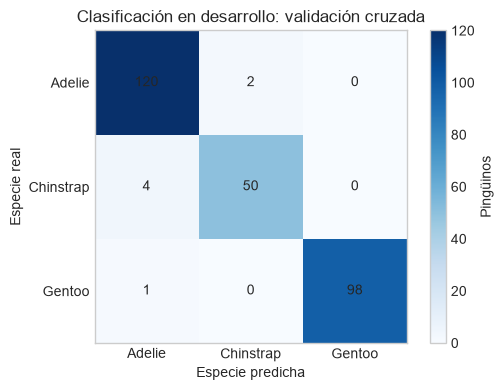

,precision,recall,f1-score,support
Adelie,0.9600,0.9836,0.9717,122.0000
Chinstrap,0.9615,0.9259,0.9434,54.0000
Gentoo,1.0000,0.9899,0.9949,99.0000
accuracy,0.9745,0.9745,0.9745,0.9745
macro avg,0.9738,0.9665,0.9700,275.0000
weighted avg,0.9747,0.9745,0.9745,275.0000


,modelo,accuracy
0,Mayoría: predicciones fuera de fold,0.4436
1,Regresión logística fuera de fold,0.9745


El par con más confusiones es **Adelie–Chinstrap**, con **6** errores entre ambas direcciones. El promedio macro da igual peso a cada especie, aunque tengan distintos tamaños.

In [8]:
def mostrar_matriz(matriz, etiquetas, titulo):
    fig, ax = plt.subplots(figsize=(5.5, 4))
    imagen = ax.imshow(matriz, cmap="Blues")
    for fila in range(len(etiquetas)):
        for columna in range(len(etiquetas)):
            ax.text(columna, fila, str(matriz[fila, columna]), ha="center", va="center")
    ax.set(
        title=titulo, xlabel="Especie predicha", ylabel="Especie real",
        xticks=range(len(etiquetas)), yticks=range(len(etiquetas)),
        xticklabels=etiquetas, yticklabels=etiquetas,
    )
    ax.grid(False)
    fig.colorbar(imagen, ax=ax, label="Pingüinos")
    plt.tight_layout()
    plt.show()

modelo_clf = pipeline_clasificacion(clone(logistica))
pred_clf = cross_val_predict(modelo_clf, X_dev, y_dev, cv=folds)
matriz_clf = confusion_matrix(y_dev, pred_clf, labels=clases)
mostrar_matriz(matriz_clf, clases, "Clasificación en desarrollo: validación cruzada")
reporte_clf = pd.DataFrame(classification_report(
    y_dev, pred_clf, labels=clases, output_dict=True, zero_division=0
)).T
display(reporte_clf.round(4))

comparacion_clf = pd.DataFrame([
    {
        "modelo": "Mayoría: predicciones fuera de fold",
        "accuracy": accuracy_score(y_dev, cross_val_predict(
            pipeline_clasificacion(DummyClassifier(strategy="most_frequent")),
            X_dev, y_dev, cv=folds,
        )),
    },
    {"modelo": "Regresión logística fuera de fold", "accuracy": accuracy_score(y_dev, pred_clf)},
])
display(comparacion_clf.round(4))

confusiones = np.triu(matriz_clf + matriz_clf.T, k=1)
a, b = np.unravel_index(confusiones.argmax(), confusiones.shape)
display(Markdown(
    f"El par con más confusiones es **{clases[a]}–{clases[b]}**, "
    f"con **{confusiones[a, b]}** errores entre ambas direcciones. "
    "El promedio macro da igual peso a cada especie, aunque tengan distintos tamaños."
))

<a id="ejercicio-9"></a>
## 9. Métricas de regresión

### Cálculo manual

Para valores reales `[10,12,18,20]` y predicciones `[11,10,17,26]`, el error se define como predicción menos real.

In [9]:
real_manual = np.array([10, 12, 18, 20])
pred_manual = np.array([11, 10, 17, 26])
errores = pred_manual - real_manual
display(pd.DataFrame({
    "real": real_manual, "predicho": pred_manual, "error": errores,
    "absoluto": np.abs(errores), "cuadrado": errores**2,
}))
print("MAE = (1+2+1+6)/4 =", np.abs(errores).mean())
print("RMSE = raíz((1+4+1+36)/4) =", np.sqrt((errores**2).mean()))

,real,predicho,error,absoluto,cuadrado
0,10,11,1,1,1
1,12,10,-2,2,4
2,18,17,-1,1,1
3,20,26,6,6,36


MAE = (1+2+1+6)/4 = 2.5
RMSE = raíz((1+4+1+36)/4) = 3.24037034920393


El error de 6 aporta 36 al promedio cuadrático; por eso pesa más en RMSE. Para errores grandes especialmente costosos usaría RMSE como métrica principal.

### Masa corporal fuera de fold

Se predice masa con longitud de pico, profundidad de pico y aleta. Los registros sin masa no pueden evaluarse; faltantes de las entradas se imputan dentro de cada fold.

In [10]:
regresion_lineal = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
    ("modelo", LinearRegression()),
])
predicciones_reg["Regresión lineal"] = cross_val_predict(
    regresion_lineal, X_reg, y_reg, cv=folds_reg
)
tabla_regresion = pd.DataFrame({
    nombre: metricas_regresion(y_reg, predicho)
    for nombre, predicho in predicciones_reg.items()
}).T
display(tabla_regresion.round(3))

numerico = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
categorico = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore")),
])
regresion_con_especie = Pipeline([
    ("preparar", ColumnTransformer([
        ("medidas", numerico, MEDIDAS_REG),
        ("especie", categorico, ["species"]),
    ])),
    ("modelo", LinearRegression()),
])
pred_con_especie = cross_val_predict(
    regresion_con_especie, desarrollo_reg[MEDIDAS_REG + ["species"]], y_reg, cv=folds_reg
)
display(pd.DataFrame({
    "Sin especie": metricas_regresion(y_reg, predicciones_reg["Regresión lineal"]),
    "Con especie conocida": metricas_regresion(y_reg, pred_con_especie),
}).T.round(3))

mae_lineal = tabla_regresion.loc["Regresión lineal", "MAE (g)"]
mae_media = tabla_regresion.loc["Media", "MAE (g)"]
display(Markdown(
    f"La regresión lineal tiene MAE de **{mae_lineal:.1f} g**, frente a "
    f"**{mae_media:.1f} g** de la media. MAE expresa error absoluto promedio; "
    "RMSE da mayor peso a los errores grandes."
))

,MAE (g),RMSE (g),R2
Media,683.870,807.424,-0.008
Mediana,675.229,820.331,-0.040
Regresión lineal,323.477,406.160,0.745


,MAE (g),RMSE (g),R2
Sin especie,323.477,406.160,0.745
Con especie conocida,266.723,333.911,0.828


La regresión lineal tiene MAE de **323.5 g**, frente a **683.9 g** de la media. MAE expresa error absoluto promedio; RMSE da mayor peso a los errores grandes.

Un R² negativo significa que la suma de errores cuadrados supera la referencia basada en la media de los valores evaluados; por sí solo no demuestra sobreajuste.

Incorporar especie cambia la pregunta: ahora se estima masa suponiendo que la especie ya se conoce. Puede mejorar la estimación, pero no sirve para un escenario donde esa información aún no está disponible.

<a id="ejercicio-10"></a>
## 10. Clustering y estabilidad

Se agrupan las cuatro medidas imputadas y estandarizadas, sin usar especie, isla ni sexo. Para cada K entre 2 y 6 se repiten cinco semillas, con diez inicializaciones por ajuste.

El criterio previo es mayor silhouette medio; si la diferencia no supera 0,02, se prefiere el menor K entre las soluciones con desvío de silhouette menor a 0,02. Si ninguna cumple ese límite, se informa la inestabilidad. Se conserva la semilla 42 como ejecución representativa, sin elegirla según su resultado.

,K,semilla,silhouette,inercia
0,2,1,0.5331,452.7727
1,2,7,0.5331,452.7727
2,2,21,0.5331,452.7727
3,2,42,0.5331,452.7727
4,2,84,0.5331,452.7727
5,3,1,0.4548,297.4710
6,3,7,0.4548,297.4710
7,3,21,0.4548,297.4710
8,3,42,0.4548,297.4710
9,3,84,0.4548,297.4710


,mean,std,min,max
K,,,,
2,0.5331,0.0000,0.5331,0.5331
3,0.4548,0.0000,0.4548,0.4548
4,0.4060,0.0000,0.4060,0.4060
5,0.3854,0.0001,0.3852,0.3855
6,0.3717,0.0008,0.3713,0.3731


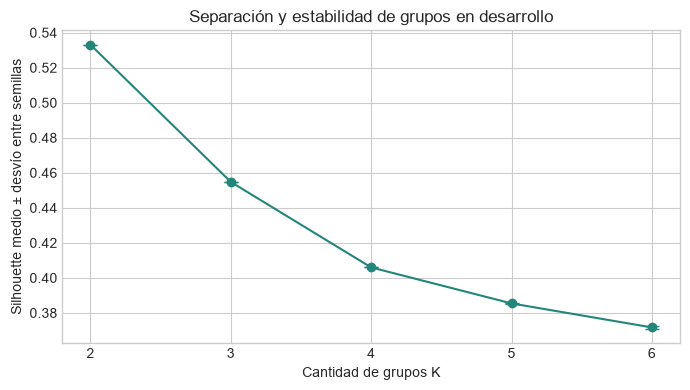

Se elige **K=2** con el criterio fijado: silhouette medio **0.5331** y desvío **0.0000**.

In [11]:
preparador_clusters = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
X_clusters = preparador_clusters.fit_transform(desarrollo[MEDIDAS])
semillas_clusters = [1, 7, 21, 42, 84]
resultados_clusters = []
etiquetas_clusters = {}
with threadpool_limits(limits=1):
    for k in range(2, 7):
        for semilla in semillas_clusters:
            modelo = KMeans(n_clusters=k, n_init=10, random_state=semilla)
            etiquetas = modelo.fit_predict(X_clusters)
            etiquetas_clusters[(k, semilla)] = etiquetas
            resultados_clusters.append({
                "K": k, "semilla": semilla,
                "silhouette": silhouette_score(X_clusters, etiquetas),
                "inercia": modelo.inertia_,
            })

ensayos_clusters = pd.DataFrame(resultados_clusters)
resumen_clusters = ensayos_clusters.groupby("K")["silhouette"].agg(["mean", "std", "min", "max"])
display(ensayos_clusters.round(4))
display(resumen_clusters.round(4))

mejor_silhouette = resumen_clusters["mean"].max()
admisibles = resumen_clusters.loc[
    (resumen_clusters["mean"] >= mejor_silhouette - 0.02)
    & (resumen_clusters["std"] < 0.02)
]
if admisibles.empty:
    k_elegido = int(resumen_clusters["mean"].idxmax())
    print("No hubo una solución que cumpliera el umbral de estabilidad.")
else:
    k_elegido = int(admisibles.index.min())
grupos = etiquetas_clusters[(k_elegido, SEMILLA)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    resumen_clusters.index, resumen_clusters["mean"],
    yerr=resumen_clusters["std"], marker="o", capsize=5, color="#23867a",
)
ax.set(
    title="Separación y estabilidad de grupos en desarrollo",
    xlabel="Cantidad de grupos K", ylabel="Silhouette medio ± desvío entre semillas",
    xticks=range(2, 7),
)
plt.tight_layout()
plt.show()
display(Markdown(
    f"Se elige **K={k_elegido}** con el criterio fijado: "
    f"silhouette medio **{resumen_clusters.loc[k_elegido, 'mean']:.4f}** "
    f"y desvío **{resumen_clusters.loc[k_elegido, 'std']:.4f}**."
))

In [12]:
medidas_imputadas = pd.DataFrame(
    preparador_clusters.named_steps["imputar"].transform(desarrollo[MEDIDAS]),
    index=desarrollo.index, columns=MEDIDAS,
)
perfiles = medidas_imputadas.assign(grupo=grupos).groupby("grupo")[MEDIDAS].median()
perfiles["individuos"] = pd.Series(grupos).value_counts().sort_index()
display(perfiles.round(2))
display(pd.crosstab(pd.Series(grupos, index=desarrollo.index, name="grupo"), desarrollo["species"]))
display(pd.crosstab(pd.Series(grupos, index=desarrollo.index, name="grupo"), desarrollo["island"]))

sil_individual = silhouette_samples(X_clusters, grupos)
contexto_clusters = desarrollo[["species", "island", "sex", *MEDIDAS]].copy()
contexto_clusters["grupo"] = grupos
contexto_clusters["silhouette"] = sil_individual
casos_frontera = contexto_clusters.sort_values("silhouette").head(10)
display(casos_frontera.round(3))
print("Silhouette negativa:", int((sil_individual < 0).sum()))
print("Silhouette menor a 0,10:", int((sil_individual < 0.10).sum()))

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,individuos
grupo,,,,,
0,47.45,14.95,216.0,5075.0,98
1,40.60,18.50,192.0,3700.0,177


species,Adelie,Chinstrap,Gentoo
grupo,,,
0,0,0,98
1,122,54,1


island,Biscoe,Dream,Torgersen
grupo,,,
0,98,0,0
1,36,98,43


,species,island,sex,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,grupo,silhouette
313,Chinstrap,Dream,male,52.0,20.7,210.0,4800.0,1,0.053
315,Chinstrap,Dream,male,53.5,19.9,205.0,4500.0,1,0.100
342,Chinstrap,Dream,male,50.8,19.0,210.0,4100.0,1,0.109
339,Chinstrap,Dream,male,55.8,19.8,207.0,4000.0,1,0.112
305,Chinstrap,Dream,male,52.8,20.0,205.0,4550.0,1,0.113
321,Chinstrap,Dream,male,50.8,18.5,201.0,4450.0,1,0.117
323,Chinstrap,Dream,male,49.0,19.6,212.0,4300.0,1,0.123
289,Chinstrap,Dream,male,52.0,18.1,201.0,4050.0,1,0.152
293,Chinstrap,Dream,female,58.0,17.8,181.0,3700.0,1,0.194
309,Chinstrap,Dream,male,51.0,18.8,203.0,4100.0,1,0.212


Silhouette negativa: 0
Silhouette menor a 0,10: 1


Las barras de error permiten ver si la separación cambia con la inicialización. Los perfiles describen tamaños corporales en mm y gramos; los casos de silhouette baja o negativa están cerca de una frontera o se parecen más a otro grupo y requieren revisión.

La tabla de especies se consulta después de elegir K. Un grupo puede mezclar especies y una buena separación geométrica no prueba un significado biológico. Los grupos podrían orientar el muestreo de perfiles poco frecuentes, pero esa utilidad necesitaría validación adicional.

<a id="ejercicio-11"></a>
## 11. Validación cruzada del procedimiento completo

Se comparan regresión logística y árbol con los cinco folds de clasificación ya fijados. Se muestran tanto los resultados individuales como su dispersión.

In [13]:
candidatos = {
    "Regresión logística": pipeline_clasificacion(clone(logistica)),
    "Árbol sin límite": pipeline_clasificacion(
        DecisionTreeClassifier(random_state=SEMILLA)
    ),
}
resultados_cv = {}
registros_cv = []
for nombre, modelo in candidatos.items():
    resultado = cross_validate(
        modelo, X_dev, y_dev, cv=folds,
        scoring=["accuracy", "f1_macro"], error_score="raise",
    )
    resultados_cv[nombre] = resultado
    for i in range(len(folds)):
        registros_cv.append({
            "modelo": nombre, "fold": i + 1,
            "accuracy": resultado["test_accuracy"][i],
            "F1 macro": resultado["test_f1_macro"][i],
        })
tabla_folds = pd.DataFrame(registros_cv)
resumen_cv = tabla_folds.groupby("modelo")[["accuracy", "F1 macro"]].agg(
    ["mean", "std", "min", "max"]
)
display(tabla_folds.round(4))
display(resumen_cv.round(4))

media_logistica = resultados_cv["Regresión logística"]["test_f1_macro"].mean()
media_arbol = resultados_cv["Árbol sin límite"]["test_f1_macro"].mean()
provisional = "Regresión logística" if media_logistica >= media_arbol - 0.005 else "Árbol sin límite"
display(Markdown(
    f"La elección provisional es **{provisional}**, aplicando F1 macro "
    "y la tolerancia de 0,005 prevista al inicio."
))

,modelo,fold,accuracy,F1 macro
0,Regresión logística,1,0.9636,0.9533
1,Regresión logística,2,1.0000,1.0000
2,Regresión logística,3,1.0000,1.0000
3,Regresión logística,4,0.9273,0.9132
4,Regresión logística,5,0.9818,0.9784
5,Árbol sin límite,1,0.9455,0.9320
6,Árbol sin límite,2,0.9636,0.9564
7,Árbol sin límite,3,0.9818,0.9773
8,Árbol sin límite,4,0.8909,0.8704
9,Árbol sin límite,5,0.9818,0.9848


accuracy                         F1 macro                  \
                        mean     std     min     max     mean     std     min   
modelo                                                                          
Regresión logística   0.9745  0.0304  0.9273  1.0000   0.9690  0.0366  0.9132   
Árbol sin límite      0.9527  0.0377  0.8909  0.9818   0.9442  0.0461  0.8704   

                             
                        max  
modelo                       
Regresión logística  1.0000  
Árbol sin límite     0.9848

La elección provisional es **Regresión logística**, aplicando F1 macro y la tolerancia de 0,005 prevista al inicio.

El promedio solo no muestra cuánto cambia el resultado entre folds. Una dispersión grande advierte sensibilidad a las filas disponibles, aunque no identifica por sí sola su causa.

Compartir folds evita atribuir a los modelos diferencias causadas por particiones distintas. Imputación, escala y cualquier selección deben ajustarse en el entrenamiento de cada fold. La prueba permanece fuera de este proceso.

<a id="ejercicio-12"></a>
## 12. Complejidad y profundidad del árbol

Se comparan profundidades 1, 2, 3, 5, 8 y sin límite. Se registran accuracy y F1 macro de entrenamiento y validación. La selección usa validación y prefiere la menor profundidad dentro de 0,005 del mejor F1 macro.

,profundidad,entrenamiento_accuracy,entrenamiento_accuracy_desvío,entrenamiento_f1_macro,entrenamiento_f1_macro_desvío,validación_accuracy,validación_accuracy_desvío,validación_f1_macro,validación_f1_macro_desvío
0,1,0.7927,0.0052,0.5947,0.0031,0.7891,0.0207,0.5920,0.0115
1,2,0.9600,0.0087,0.9520,0.0103,0.9527,0.0330,0.9435,0.0385
2,3,0.9664,0.0109,0.9602,0.0134,0.9491,0.0350,0.9385,0.0419
3,5,0.9945,0.0038,0.9944,0.0040,0.9527,0.0377,0.9442,0.0461
4,8,0.9973,0.0025,0.9977,0.0021,0.9527,0.0377,0.9442,0.0461
5,None,0.9973,0.0025,0.9977,0.0021,0.9527,0.0377,0.9442,0.0461


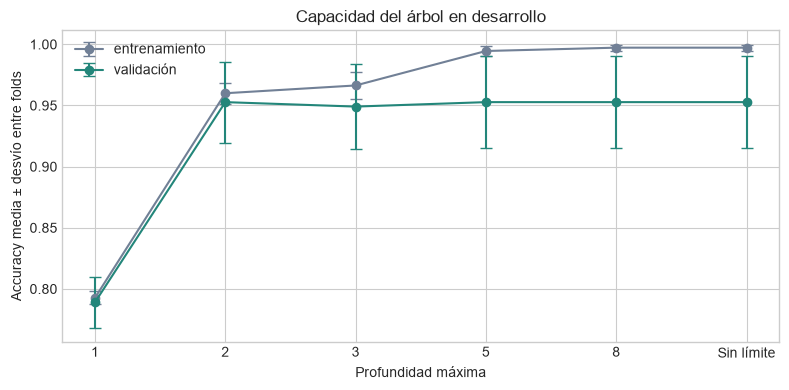

El árbol elegido tiene profundidad **2**, F1 macro de validación **0.9435** y desvío **0.0385**. Al compararlo con logística, la elección final es **Regresión logística**.

In [14]:
profundidades = [1, 2, 3, 5, 8, None]
filas_profundidad = []
for profundidad in profundidades:
    modelo = pipeline_clasificacion(
        DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA)
    )
    resultado = cross_validate(
        modelo, X_dev, y_dev, cv=folds, scoring=["accuracy", "f1_macro"],
        return_train_score=True, error_score="raise",
    )
    fila = {"profundidad": str(profundidad)}
    for conjunto in ["train", "test"]:
        for metrica in ["accuracy", "f1_macro"]:
            valores = resultado[f"{conjunto}_{metrica}"]
            prefijo = "entrenamiento" if conjunto == "train" else "validación"
            fila[f"{prefijo}_{metrica}"] = valores.mean()
            fila[f"{prefijo}_{metrica}_desvío"] = valores.std(ddof=1)
    filas_profundidad.append(fila)
tabla_profundidad = pd.DataFrame(filas_profundidad)
display(tabla_profundidad.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
posiciones = np.arange(len(profundidades))
for prefijo, color in [("entrenamiento", "#718096"), ("validación", "#23867a")]:
    ax.errorbar(
        posiciones, tabla_profundidad[f"{prefijo}_accuracy"],
        yerr=tabla_profundidad[f"{prefijo}_accuracy_desvío"],
        marker="o", capsize=4, label=prefijo, color=color,
    )
ax.set(
    title="Capacidad del árbol en desarrollo",
    xlabel="Profundidad máxima", ylabel="Accuracy media ± desvío entre folds",
    xticks=posiciones, xticklabels=["1", "2", "3", "5", "8", "Sin límite"],
)
ax.legend()
plt.tight_layout()
plt.show()

mejor_f1_arbol = tabla_profundidad["validación_f1_macro"].max()
elegibles = tabla_profundidad.index[
    tabla_profundidad["validación_f1_macro"] >= mejor_f1_arbol - 0.005
]
indice_arbol = int(elegibles[0])
profundidad_elegida = profundidades[indice_arbol]
fila_elegida = tabla_profundidad.loc[indice_arbol]
f1_arbol_elegido = fila_elegida["validación_f1_macro"]
nombre_final = (
    "Regresión logística" if media_logistica >= f1_arbol_elegido - 0.005
    else f"Árbol de profundidad {profundidad_elegida}"
)
display(Markdown(
    f"El árbol elegido tiene profundidad **{profundidad_elegida}**, "
    f"F1 macro de validación **{f1_arbol_elegido:.4f}** y desvío "
    f"**{fila_elegida['validación_f1_macro_desvío']:.4f}**. "
    f"Al compararlo con logística, la elección final es **{nombre_final}**."
))

In [15]:
simple = tabla_profundidad.iloc[0]
complejo = tabla_profundidad.iloc[-1]
display(Markdown(
    f"Profundidad 1 obtiene accuracy de **{simple['entrenamiento_accuracy']:.3f}** "
    f"en entrenamiento y **{simple['validación_accuracy']:.3f}** en validación: "
    "es la región de menor capacidad. "
    f"Sin límite obtiene **{complejo['entrenamiento_accuracy']:.3f}** y "
    f"**{complejo['validación_accuracy']:.3f}**, respectivamente. "
    "La brecha mayor, sin una mejora equivalente en validación, sugiere sobreajuste."
))

Profundidad 1 obtiene accuracy de **0.793** en entrenamiento y **0.789** en validación: es la región de menor capacidad. Sin límite obtiene **0.997** y **0.953**, respectivamente. La brecha mayor, sin una mejora equivalente en validación, sugiere sobreajuste.

Subajuste se espera cuando ambos desempeños son bajos para la tarea; una brecha amplia entre entrenamiento y validación sugiere sobreajuste, sin demostrarlo por sí sola.

Elegir por entrenamiento premiaría memorizar filas. Si dos configuraciones validan de forma parecida, se prefiere la más simple. La dispersión informada ayuda a no interpretar diferencias pequeñas como mejoras seguras.

<a id="ejercicio-13"></a>
## 13. Configuración congelada y evaluación final

Antes de consultar las entradas de prueba se fija el modelo elegido en desarrollo. Los predictores son las cuatro medidas corporales; especie es objetivo y las otras variables son contexto excluido. No hay selección adicional ni codificación de entradas.

Se usa imputación por mediana y estandarización. La métrica principal es F1 macro y también se informa accuracy, precisión, recall y matriz de confusión. Al ser multiclase, no hay una única clase positiva. La elección considera el F1 macro de los mismos cinco folds, con las tolerancias definidas al inicio.

In [16]:
if nombre_final == "Regresión logística":
    modelo_final = pipeline_clasificacion(clone(logistica))
    f1_validacion_final = media_logistica
    accuracy_validacion_final = resultados_cv["Regresión logística"]["test_accuracy"].mean()
    dispersion_f1_final = resultados_cv["Regresión logística"]["test_f1_macro"].std(ddof=1)
else:
    modelo_final = pipeline_clasificacion(
        DecisionTreeClassifier(max_depth=profundidad_elegida, random_state=SEMILLA)
    )
    f1_validacion_final = f1_arbol_elegido
    accuracy_validacion_final = fila_elegida["validación_accuracy"]
    dispersion_f1_final = fila_elegida["validación_f1_macro_desvío"]

configuracion_congelada = {
    "modelo": nombre_final,
    "predictores": ", ".join(MEDIDAS),
    "objetivo": "species",
    "contexto excluido": "island, sex, year",
    "imputación": "mediana ajustada en desarrollo",
    "escala": "StandardScaler ajustado en desarrollo",
    "selección adicional": "ninguna",
    "semilla": SEMILLA,
    "métrica principal": "F1 macro",
    "clase positiva": "no aplica: clasificación multiclase",
    "criterio": "F1 macro de CV; tolerancia 0,005 y preferencia por simplicidad",
    "hiperparámetros": str(modelo_final.named_steps["modelo"].get_params()),
    "consulta de prueba": "después de fijar este registro; solo en la celda siguiente",
}
display(pd.Series(configuracion_congelada).to_frame("configuración"))
configuracion_antes_prueba = configuracion_congelada.copy()

,configuración
modelo,Regresión logística
predictores,"bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g"
objetivo,species
contexto excluido,"island, sex, year"
imputación,mediana ajustada en desarrollo
escala,StandardScaler ajustado en desarrollo
selección adicional,ninguna
semilla,42
métrica principal,F1 macro
clase positiva,no aplica: clasificación multiclase


,validación: media por fold,prueba final
accuracy,0.9745,1.0
F1 macro,0.9690,1.0


,precision,recall,f1-score,support
Adelie,1.0,1.0,1.0,30.0
Chinstrap,1.0,1.0,1.0,14.0
Gentoo,1.0,1.0,1.0,25.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,69.0
weighted avg,1.0,1.0,1.0,69.0


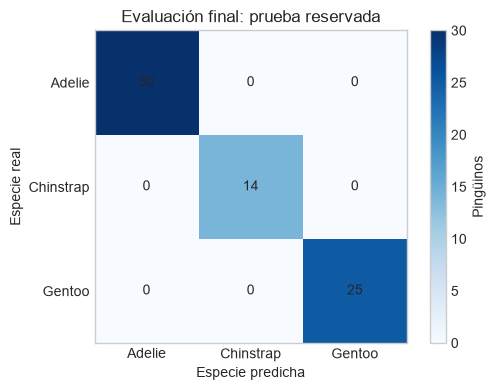

Se consultó la prueba después de congelar variables, pipeline, modelo, hiperparámetros y criterio. Sobre **69 individuos**, accuracy es **1.0000** y F1 macro **1.0000**. La diferencia de F1 frente a validación es **+0.0310**, con desvío entre folds de **0.0366**. No se ajustó el modelo después de este resultado.

In [17]:
modelo_final.fit(X_dev, y_dev)
pred_prueba = modelo_final.predict(prueba[MEDIDAS])
y_prueba = prueba["species"]

accuracy_prueba = accuracy_score(y_prueba, pred_prueba)
f1_prueba = f1_score(y_prueba, pred_prueba, average="macro")
matriz_prueba = confusion_matrix(y_prueba, pred_prueba, labels=clases)

display(pd.DataFrame({
    "validación: media por fold": [accuracy_validacion_final, f1_validacion_final],
    "prueba final": [accuracy_prueba, f1_prueba],
}, index=["accuracy", "F1 macro"]).round(4))
display(pd.DataFrame(classification_report(
    y_prueba, pred_prueba, labels=clases, output_dict=True, zero_division=0
)).T.round(4))
mostrar_matriz(matriz_prueba, clases, "Evaluación final: prueba reservada")
assert configuracion_congelada == configuracion_antes_prueba
pd.testing.assert_frame_equal(datos, original)
assert len(pred_prueba) == len(idx_prueba)
display(Markdown(
    f"Se consultó la prueba después de congelar variables, pipeline, modelo, "
    f"hiperparámetros y criterio. Sobre **{len(y_prueba)} individuos**, "
    f"accuracy es **{accuracy_prueba:.4f}** y F1 macro **{f1_prueba:.4f}**. "
    f"La diferencia de F1 frente a validación es "
    f"**{f1_prueba - f1_validacion_final:+.4f}**, con desvío entre folds "
    f"de **{dispersion_f1_final:.4f}**. No se ajustó el modelo después de este resultado."
))

La diferencia se interpreta junto con la variabilidad de validación y el tamaño reducido de prueba. El desvío entre folds no es un intervalo de confianza ni demuestra que dos desempeños sean iguales.

La evaluación respalda el resultado sobre individuos de esta población de referencia. No demuestra transferencia a otras regiones, especies o condiciones de medición. Si la prueba motivara cambiar el modelo, se necesitaría otra muestra independiente para evaluar ese nuevo procedimiento.

## Ficha final y reproducibilidad

| Elemento | Registro |
|---|---|
| Fuente y copia | CSV original conservado en memoria, con URL, fecha de acceso y SHA-256 |
| Unidad y población | Un pingüino; población representada por las islas y años de Palmer Penguins |
| Separación | 80/20 estratificada por especie, semilla 42; índices incluidos y guardados temporalmente |
| Desarrollo | EDA, imputación, escala y validación en cinco folds |
| Clasificación | Cuatro medidas; logística y árboles; elección por F1 macro |
| Regresión | Tres medidas; media, mediana y regresión lineal sobre las mismas filas y folds |
| Clustering | Cuatro medidas, K de 2 a 6, cinco semillas; especie reservada para interpretación |
| Prueba | Una evaluación tras el registro de configuración congelada |
| Repetición | Reiniciar el kernel y ejecutar todo; requiere Internet para descargar el CSV |

Antes de ver resultados se fijaron población, variables principales, partición, semillas, métricas y criterios de comparación. Después de validar se eligieron K, profundidad y familia final. La prueba no intervino en esas elecciones.

Como límites quedan el tamaño del conjunto, la falta de identificador individual para una verificación externa y el alcance geográfico y temporal. Una siguiente comprobación sería evaluar muestras nuevas o ejecutar la extensión por isla y año como experimento separado.